# Evaluación Parcial N°2: Machine Learning
## Inteligencia Musical y Predicción de Popularidad de Canciones (Spotify Tracks)
|Campo|Detalle|
|---|---|
|Integrantes| Catalina Villegas y Javiera Fuenzalida|
|Sección| 002D|
|Asignatura| Machine Learning|
|Docente| Ignacio Meza|

### **Metodología CRISP-DM**
El proyecto se desarrolla bajo el estándar CRISP-DM (*Cross-Industry Standard Process for Data Mining*):
1. **Comprensión del Negocio:** Definición de objetivos para estimar la popularidad y optimizar decisiones de difusión musical.
2. **Comprensión de los Datos:** Exploración del dataset Spotify Tracks (125 géneros y atributos de audio).
3. **Preparación de los Datos:** Limpieza de duplicados, tratamiento de valores nulos, acotamiento de outliers y codificación.
4. **Modelado:** Selección e implementación de algoritmos de regresión/clasificación.
5. **Evaluación:** Validación técnica de métricas predictivas frente a KPIs de negocio.
6. **Despliegue:** Documentación reproducible en formato Notebook (`.ipynb`) y Markdown (`.md`).

### **Fuentes de Datos y Herramientas Utilizadas**
* **Fuente de Datos:** Dataset `Spotify_Tracks_Dataset.csv` de Spotify con ~114,000 canciones y 20 variables (metadatos y variables acústicas como `danceability`, `energy`, `loudness`, `valence`, etc. Sin contar `unnamed`).
* **Google Colab / Jupyter:** Entorno colaborativo en la nube que garantiza ejecución reproducible del código.
* **Pandas & NumPy:** Procesamiento estructurado, limpieza y manipulación eficiente de matrices.
* **Matplotlib & Seaborn:** Generación de gráficos exploratorios para detección de patrones y sesgos.

###**Contexto y Descripción del problema de negocio**

Las plataformas de streaming musical operan en un entorno altamente dinámico donde miles de canciones son lanzadas diariamente. Para discográficas, creadores de contenido y la propia plataforma, anticipar el nivel de adopción o popularidad de un track permite optimizar la inversión en marketing, definir listas de reproducción editoriales y maximizar el engagement de la audiencia. Este proyecto aborda la necesidad de identificar qué características acústicas y metadatos influyen directamente en la popularidad de una pista musical en Spotify.

El dataset entregado contiene información sobre las pistas de Spotify alrededor de 125 géneros, además de contener información y especificaciones sobre los audios y su metadata.

###**Objetivos del Proyecto**

El objetivo general es desarrollar una solución analítica de Machine Learning para predecir la popularidad de las canciones en Spotify a partir de sus atributos acústicos y metadatos.

* Implementar el pipeline completo de ciencia de datos bajo la metodología CRISP-DM.

* Analizar y preparar el conjunto de datos resolviendo problemas de duplicados, valores faltantes y sesgos de distribución.

* Identificar los factores acústicos clave (p. ej., danceability, energy, valence) correlacionados con el éxito comercial de una canción.

### **KPIs Principales del Negocio**

**Tasa Global de Hits**

Porcentaje del catálogo con `popularity >= 70`.

**Popularidad Promedio Por género**

Identificación de géneros con mayor atractivo comercial.

**Índice de Afinidad Sonora**

Grado de correlación entre atributos acústicos clave y la popularidad.


**Duración Óptima**

Intervalo de duración (en minutos) que concentra los niveles más altos de popularidad.

##**Analizando y tratando el DataSet**

### Librerias

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import category_encoders as ce
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix, classification_report, mean_squared_error, r2_score
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTENC
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
import xgboost as xgb


### Carga Principal

In [3]:
df = pd.read_csv('..\data\Spotify_Tracks_Dataset_Clean.csv')
print(f'Dataset cargado: {df.shape[0]} filas x {df.shape[1]} columnas')
print('-' * 60)

print('\n1. PRIMERAS 5 FILAS (ejemplo completado):')
display(df.head())
print('-' * 60)
print(f"\n2. INFORMACIÓN:\n")
print(df.info())
print(f"\n3. ESTADÍSTICAS:\n{df.describe()}")

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
C:\Users\generica\AppData\Local\Temp\ipykernel_8632\1689561168.py:1: SyntaxWarning: invalid escape sequence '\d'
  df = pd.read_csv('..\data\Spotify_Tracks_Dataset_Clean.csv')


Dataset cargado: 113549 filas x 20 columnas
------------------------------------------------------------

1. PRIMERAS 5 FILAS (ejemplo completado):


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4.0,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4.0,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4.0,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3.0,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4.0,acoustic


------------------------------------------------------------

2. INFORMACIÓN:

<class 'pandas.DataFrame'>
RangeIndex: 113549 entries, 0 to 113548
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          113549 non-null  str    
 1   artists           113549 non-null  str    
 2   album_name        113549 non-null  str    
 3   track_name        113549 non-null  str    
 4   popularity        113549 non-null  int64  
 5   duration_ms       113549 non-null  int64  
 6   explicit          113549 non-null  bool   
 7   danceability      113549 non-null  float64
 8   energy            113549 non-null  float64
 9   key               113549 non-null  int64  
 10  loudness          113549 non-null  float64
 11  mode              113549 non-null  int64  
 12  speechiness       113549 non-null  float64
 13  acousticness      113549 non-null  float64
 14  instrumentalness  113549 non-null  float64
 15  

# Transformaciones


***Conversión de Duración*** (`duration_ms` a `duration_min`)
```python
df['duration_min'] = df['duration_ms'] / 60000
```
*  Los milisegundos son una unidad difícil de interpretar a simple vista . Al transformarlos a minutos, facilitamos la lectura de los datos y hacemos que las visualizaciones (como gráficos de distribución o de dispersión) sean mucho más intuitivas.
* Además reduce la magnitud numérica de la variable, lo que ayuda a evitar problemas de escala si más adelante se utilizan modelos de Machine Learning sensibles a las magnitudes (como algoritmos basados en distancias).

---

***Creación de la Variable Objetivo Binaria (`is_hit`)***
```python
UMBRAL_HIT = 70
df['is_hit'] = (df['popularity'] >= UMBRAL_HIT).astype(int)
```
* La popularidad original es una variable continua. Al aplicar un umbral estricto (\(70\)), transformamos el problema en un caso de **clasificación binaria** (\(1\) para Éxito / \(0\) para No Éxito). Esto permite entrenar modelos específicos como Random Forest.
* En el análisis de negocio, establecer un corte cuantitativo (en este caso, el percentil o valor alto de 70) es fundamental para definir qué características hacen que una canción sea considerada un éxito comercial dentro de la plataforma.


In [4]:
df['duration_min'] = df['duration_ms'] / 60000
UMBRAL_HIT = 70

df['is_hit'] = (df['popularity'] >= UMBRAL_HIT).astype(int)

In [5]:
#df['artists'].unique()  -> 31437

## Eliminación de Variables

Para optimizar el rendimiento de los modelos, evitar la redundancia y asegurar un proceso ético y eficiente, se procedió a eliminar ciertas columnas del dataset original mediante el siguiente código:

```python
# Eliminación de variables no predictivas o redundantes
columnas_a_eliminar = ['track_id', 'artists', 'album_name', 'track_name', 'duration_ms']
df.drop(columns=columnas_a_eliminar, inplace=True, errors='ignore')

df.info()
```

### Justificación Técnica y Metodológica

* **`track_id` (Identificador Único):** Es un código alfanumérico que funciona estrictamente como clave primaria. Al no poseer un patrón matemático ni relación causal con el éxito de una canción, su inclusión solo aportaría ruido innecesario al modelo.
* **`album_name` y `track_name` (Texto Libre):** Son variables de texto de alta cardinalidad. Al no realizar un análisis de procesamiento de lenguaje natural (NLP) sobre los títulos, no aportan valor predictivo directo y complicarían innecesariamente la estructura de los datos.
* **`duration_ms` (Redundancia):** Al haber creado previamente la variable `duration_min` (duración en minutos), mantener los milisegundos originales genera **multicolinealidad perfecta** (información duplicada en diferentes escalas). Su eliminación simplifica el dataset y facilita la interpretación visual de los datos para el equipo.


In [ ]:
df.drop(columns=['track_id'], inplace=True)
df.drop(columns=['album_name'], inplace=True)
df.drop(columns=['track_name'], inplace=True)
df.drop(columns=['duration_ms'], inplace=True)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 113549 entries, 0 to 113548
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   artists           113549 non-null  str    
 1   popularity        113549 non-null  int64  
 2   explicit          113549 non-null  bool   
 3   danceability      113549 non-null  float64
 4   energy            113549 non-null  float64
 5   key               113549 non-null  int64  
 6   loudness          113549 non-null  float64
 7   mode              113549 non-null  int64  
 8   speechiness       113549 non-null  float64
 9   acousticness      113549 non-null  float64
 10  instrumentalness  113549 non-null  float64
 11  liveness          113549 non-null  float64
 12  valence           113549 non-null  float64
 13  tempo             113549 non-null  float64
 14  time_signature    113549 non-null  float64
 15  track_genre       113549 non-null  str    
 16  duration_min      113549 non-nu

## Codificación Variables Categoricas

In [ ]:
# Codificacion de variables categoricas
encoder_binario = ce.BinaryEncoder(cols=['track_genre'])
encoder = ce.TargetEncoder(cols=['artists'], smoothing=10.0)



### Normalización y estandarización 

In [ ]:
variables_sesgadas = ['speechiness', 'acousticness', 'instrumentalness', 'liveness', 'duration_min']
for col in variables_sesgadas:
    df[col] = np.log1p(df[col])

columnas_a_estandarizar = [
    'danceability', 'energy', 'loudness', 'tempo',
    'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'duration_min'
]

scaler = StandardScaler()


# Entrenamiento

## Prediciendo HIT

In [ ]:
X= df.drop(columns=['is_hit', 'popularity'])
y = df['is_hit']
X = encoder_binario.fit_transform(X)
X['artists_encoded'] = encoder.fit_transform(X['artists'], y)
X = X.drop(columns=['artists'])

X[columnas_a_estandarizar]= scaler.fit_transform(X[columnas_a_estandarizar])
X.info()



<class 'pandas.DataFrame'>
RangeIndex: 113549 entries, 0 to 113548
Data columns (total 22 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   explicit          113549 non-null  bool   
 1   danceability      113549 non-null  float64
 2   energy            113549 non-null  float64
 3   key               113549 non-null  int64  
 4   loudness          113549 non-null  float64
 5   mode              113549 non-null  int64  
 6   speechiness       113549 non-null  float64
 7   acousticness      113549 non-null  float64
 8   instrumentalness  113549 non-null  float64
 9   liveness          113549 non-null  float64
 10  valence           113549 non-null  float64
 11  tempo             113549 non-null  float64
 12  time_signature    113549 non-null  float64
 13  track_genre_0     113549 non-null  int64  
 14  track_genre_1     113549 non-null  int64  
 15  track_genre_2     113549 non-null  int64  
 16  track_genre_3     113549 non-nu

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")


Shape of X_train: (90839, 22)
Shape of X_test: (22710, 22)
Shape of y_train: (90839,)
Shape of y_test: (22710,)


### Antes del Sobremuestreo 

Solo para mostrar el pq debemos duplicar los datos ya que el modelo se puso flojito jeje 

Se uso RandomForestClassifier y LGBMClassifier

In [12]:
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [ ]:
y_true_rf = y_test
y_pred_rf = clf.predict(X_test)

Classification Report RandomForestClassifier:
               precision    recall  f1-score   support

           0       0.98      0.99      0.99     21589
           1       0.81      0.60      0.69      1121

    accuracy                           0.97     22710
   macro avg       0.90      0.80      0.84     22710
weighted avg       0.97      0.97      0.97     22710



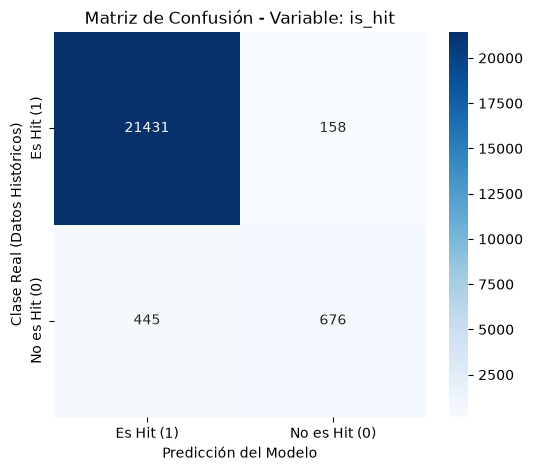

In [14]:
matriz = confusion_matrix(y_true_rf, y_pred_rf)

print("Classification Report RandomForestClassifier:\n", classification_report(y_true_rf, y_pred_rf))


plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Es Hit (1)", "No es Hit (0)"],
    yticklabels=["Es Hit (1)", "No es Hit (0)"],
)

plt.title("Matriz de Confusión - Variable: is_hit")
plt.xlabel("Predicción del Modelo")
plt.ylabel("Clase Real (Datos Históricos)")
plt.savefig('../images/matriz_RFC.png')
plt.show()

In [15]:
conteos = pd.Series(y_train).value_counts()

# Extraemos la cantidad exacta de cada uno
no_hits = conteos.get(0, 0)
hits = conteos.get(1, 0)
total = len(y_train)

porcentaje_hits = (hits / total) * 100
porcentaje_no_hits = (no_hits / total) * 100

# Evitamos división por cero en caso de que no hubiera hits
ratio_directo = no_hits / hits if hits > 0 else 0 

print("=== DIAGNÓSTICO DE DESBALANCEO ===")
print(f"Total de datos analizados: {total:,}")
print(f"Clase 0 (No Hit): {no_hits:,} ({porcentaje_no_hits:.2f}%)")
print(f"Clase 1 (Hit):    {hits:,} ({porcentaje_hits:.2f}%)")
print(f"Ratio de desbalanceo: {ratio_directo:.2f}:1")

=== DIAGNÓSTICO DE DESBALANCEO ===
Total de datos analizados: 90,839
Clase 0 (No Hit): 86,492 (95.21%)
Clase 1 (Hit):    4,347 (4.79%)
Ratio de desbalanceo: 19.90:1


In [16]:
# Calculamos el ratio de desbalanceo para alimentar al modelo
# Si el 4.5% son hits, el ratio de negativos a positivos es aprox. 21 

clf_lgb = LGBMClassifier(
    scale_pos_weight=ratio_directo,
    max_depth=6,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1
)
clf_lgb.fit(X_train, y_train)


[LightGBM] [Info] Number of positive: 4347, number of negative: 86492
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003348 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2833
[LightGBM] [Info] Number of data points in the train set: 90839, number of used features: 22
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.047854 -> initscore=-2.990566
[LightGBM] [Info] Start training from score -2.990566


,max_depth,6
,learning_rate,0.05
,random_state,42
,n_jobs,-1
,scale_pos_weight,np.float64(19.89694041867955)
,boosting_type,'gbdt'
,num_leaves,31
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None


In [ ]:
y_true_lgbm = y_test
y_pred_lgbm= clf_lgb.predict(X_test)

Classification ReportLGBMClassifier:
               precision    recall  f1-score   support

           0       1.00      0.90      0.95     21589
           1       0.35      0.98      0.51      1121

    accuracy                           0.91     22710
   macro avg       0.67      0.94      0.73     22710
weighted avg       0.97      0.91      0.93     22710



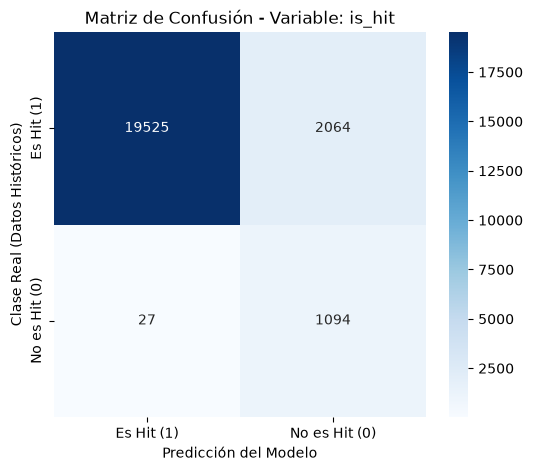

In [18]:
matriz = confusion_matrix(y_true_lgbm, y_pred_lgbm)
print("Classification ReportLGBMClassifier:\n", classification_report(y_true_lgbm, y_pred_lgbm))


plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Es Hit (1)", "No es Hit (0)"],
    yticklabels=["Es Hit (1)", "No es Hit (0)"],
)

plt.title("Matriz de Confusión - Variable: is_hit")
plt.xlabel("Predicción del Modelo")
plt.ylabel("Clase Real (Datos Históricos)")
plt.savefig('../images/matriz1_LGBMC.png')
plt.show()

### Aplicando Sobremuestreo

tambien se usan randomForestClassifier y LGBMClassifier

In [ ]:
columnas_binarias = ['track_genre_0','track_genre_1','track_genre_2','track_genre_3','track_genre_4','track_genre_5','track_genre_6'] 

smote_nc = SMOTENC(categorical_features=columnas_binarias, random_state=42)
X_train_resampled, y_train_resampled = smote_nc.fit_resample(X_train, y_train)

Classification Report RandomForestClassifier:
               precision    recall  f1-score   support

           0       0.99      0.97      0.98     21589
           1       0.56      0.80      0.66      1121

    accuracy                           0.96     22710
   macro avg       0.77      0.89      0.82     22710
weighted avg       0.97      0.96      0.96     22710



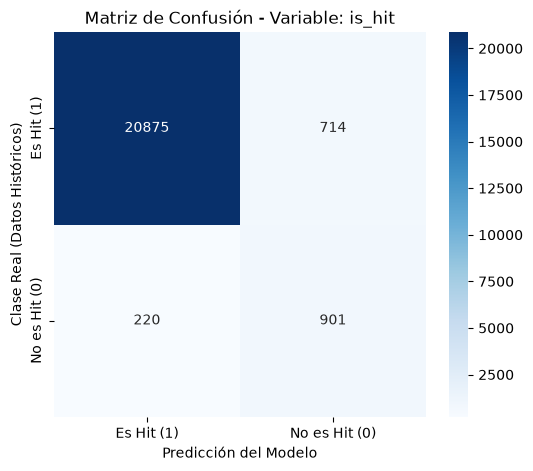

In [21]:
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train_resampled, y_train_resampled)
y_true_rf = y_test
y_pred_rf = clf.predict(X_test)


matriz = confusion_matrix(y_true_rf, y_pred_rf)

print("Classification Report RandomForestClassifier:\n", classification_report(y_true_rf, y_pred_rf))


plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Es Hit (1)", "No es Hit (0)"],
    yticklabels=["Es Hit (1)", "No es Hit (0)"],
)

plt.title("Matriz de Confusión - Variable: is_hit")
plt.xlabel("Predicción del Modelo")
plt.ylabel("Clase Real (Datos Históricos)")
plt.savefig('../images/matriz2_RFC.png')
plt.show()

In [22]:
conteos = pd.Series(y_train_resampled).value_counts()

no_hits = conteos.get(0, 0)
hits = conteos.get(1, 0)
total = len(y_train_resampled)

porcentaje_hits = (hits / total) * 100
porcentaje_no_hits = (no_hits / total) * 100

ratio_directo = no_hits / hits if hits > 0 else 0 

print("=== DIAGNÓSTICO DE DESBALANCEO ===")
print(f"Total de datos analizados: {total:,}")
print(f"Clase 0 (No Hit): {no_hits:,} ({porcentaje_no_hits:.2f}%)")
print(f"Clase 1 (Hit):    {hits:,} ({porcentaje_hits:.2f}%)")
print(f"Ratio de desbalanceo: {ratio_directo:.2f}:1")

=== DIAGNÓSTICO DE DESBALANCEO ===
Total de datos analizados: 172,984
Clase 0 (No Hit): 86,492 (50.00%)
Clase 1 (Hit):    86,492 (50.00%)
Ratio de desbalanceo: 1.00:1


[LightGBM] [Info] Number of positive: 86492, number of negative: 86492
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006550 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3090
[LightGBM] [Info] Number of data points in the train set: 172984, number of used features: 22
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
Classification ReportLGBMClassifier:
               precision    recall  f1-score   support

           0       1.00      0.93      0.96     21589
           1       0.42      0.92      0.58      1121

    accuracy                           0.93     22710
   macro avg       0.71      0.93      0.77     22710
weighted avg       0.97      0.93      0.94     22710



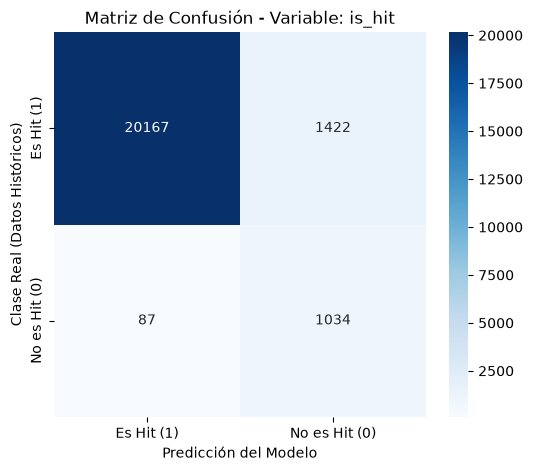

In [23]:
clf_lgb = LGBMClassifier(
    objective="binary",  
    random_state=42,
    n_estimators=200,     
    learning_rate=0.05
)

clf_lgb.fit(X_train_resampled, y_train_resampled)

y_true_lgbm = y_test
y_pred_lgbm= clf_lgb.predict(X_test)

matriz = confusion_matrix(y_true_lgbm, y_pred_lgbm)
print("Classification ReportLGBMClassifier:\n", classification_report(y_true_lgbm, y_pred_lgbm))


plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Es Hit (1)", "No es Hit (0)"],
    yticklabels=["Es Hit (1)", "No es Hit (0)"],
)

plt.title("Matriz de Confusión - Variable: is_hit")
plt.xlabel("Predicción del Modelo")
plt.ylabel("Clase Real (Datos Históricos)")
plt.savefig('../images/matriz2_LGBMC.png')
plt.show()

## Prediciendo Popularidad

Se usa RandomForestRegressor, Ridge, HistGradientBoostingRegressor y XBG

In [ ]:
X= df.drop(columns=['is_hit', 'popularity'])
y = df['popularity']
X = encoder_binario.fit_transform(X)
X['artists_encoded'] = encoder.fit_transform(X['artists'], y)
X = X.drop(columns=['artists'])
X[columnas_a_estandarizar]= scaler.fit_transform(X[columnas_a_estandarizar])
X.info()


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")

<class 'pandas.DataFrame'>
RangeIndex: 113549 entries, 0 to 113548
Data columns (total 22 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   explicit          113549 non-null  bool   
 1   danceability      113549 non-null  float64
 2   energy            113549 non-null  float64
 3   key               113549 non-null  int64  
 4   loudness          113549 non-null  float64
 5   mode              113549 non-null  int64  
 6   speechiness       113549 non-null  float64
 7   acousticness      113549 non-null  float64
 8   instrumentalness  113549 non-null  float64
 9   liveness          113549 non-null  float64
 10  valence           113549 non-null  float64
 11  tempo             113549 non-null  float64
 12  time_signature    113549 non-null  float64
 13  track_genre_0     113549 non-null  int64  
 14  track_genre_1     113549 non-null  int64  
 15  track_genre_2     113549 non-null  int64  
 16  track_genre_3     113549 non-nu

In [ ]:
modelo_rf = RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1)

modelo_rf.fit(X_train, y_train)

predicciones_rf = modelo_rf.predict(X_test)

In [ ]:
modelo_ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))

modelo_ridge.fit(X_train, y_train)

predicciones_ridge = modelo_ridge.predict(X_test)

In [ ]:
modelo_hgb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42)

modelo_hgb.fit(X_train, y_train)

predicciones_hgb= modelo_hgb.predict(X_test)

In [ ]:
modelo_regresion = xgb.XGBRegressor(
    objective="reg:squarederror", 
    n_estimators=600,
    learning_rate=0.04,
    max_depth=5,                  
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

modelo_regresion.fit(X_train, y_train)

predicciones_regresion = modelo_regresion.predict(X_test)

In [29]:
rmse = np.sqrt(mean_squared_error(y_test, predicciones_rf))
r2 = r2_score(y_test, predicciones_rf)

rdg = np.sqrt(mean_squared_error(y_test, predicciones_ridge))
r2rdg = r2_score(y_test,  predicciones_ridge)

xgb = np.sqrt(mean_squared_error(y_test, predicciones_regresion))
rxgb = r2_score(y_test,  predicciones_regresion)

hgb = np.sqrt(mean_squared_error(y_test, predicciones_hgb))
rhgb = r2_score(y_test,  predicciones_hgb)

print(f"Error promedio (RMSE): {rmse:.2f} puntos de popularidad")
print(f"Porcentaje explicado (R² Score): {r2:.2f}")

print(f"Error promedio (Ridge): {rdg:.2f} puntos de popularidad")
print(f"Porcentaje explicado (R² Score): {r2rdg:.2f}")

print(f"Error promedio (CGB): {xgb:.2f} puntos de popularidad")
print(f"Porcentaje explicado (R² Score): {rxgb:.2f}")

print(f"Error promedio (HGB): {hgb:.2f} puntos de popularidad")
print(f"Porcentaje explicado (R² Score): {rhgb:.2f}")

Error promedio (RMSE): 12.21 puntos de popularidad
Porcentaje explicado (R² Score): 0.70
Error promedio (Ridge): 16.32 puntos de popularidad
Porcentaje explicado (R² Score): 0.47
Error promedio (CGB): 12.45 puntos de popularidad
Porcentaje explicado (R² Score): 0.69
Error promedio (HGB): 12.50 puntos de popularidad
Porcentaje explicado (R² Score): 0.69


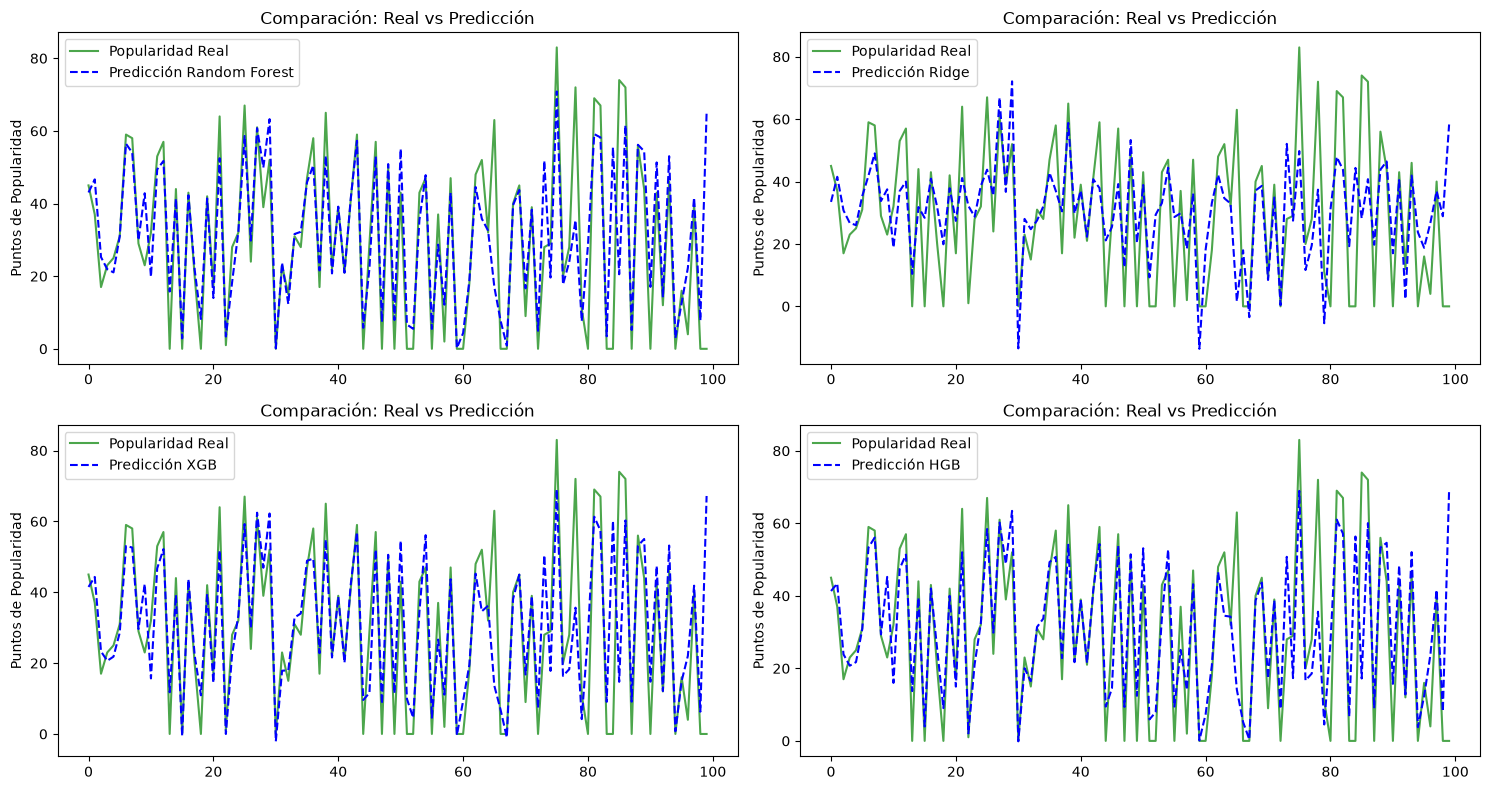

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(15, 8))


# Gráfico 1 (Arriba a la izquierda)
axs[0,0].plot(y_test.values[:100], label='Popularidad Real', color='green', alpha=0.7)
axs[0,0].plot(predicciones_rf[:100], label='Predicción Random Forest', color='blue', linestyle='--')
axs[0,0].set_title('Comparación: Real vs Predicción')
axs[0,0].set_ylabel('Puntos de Popularidad')
axs[0,0].legend()

# Gráfico 2 (Arriba a la derecha)
axs[0,1].plot(y_test.values[:100], label='Popularidad Real', color='green', alpha=0.7)
axs[0,1].plot(predicciones_ridge[:100], label='Predicción Ridge', color='blue', linestyle='--')
axs[0,1].set_title('Comparación: Real vs Predicción')
axs[0,1].set_ylabel('Puntos de Popularidad')
axs[0,1].legend()

# Gráfico 3 (Abajo a la izquierda)
axs[1,0].plot(y_test.values[:100], label='Popularidad Real', color='green', alpha=0.7)
axs[1,0].plot(predicciones_regresion[:100], label='Predicción XGB', color='blue', linestyle='--')
axs[1,0].set_title('Comparación: Real vs Predicción')
axs[1,0].set_ylabel('Puntos de Popularidad')
axs[1,0].legend()

# Gráfico 4 (Abajo a la derecha)
axs[1,1].plot(y_test.values[:100], label='Popularidad Real', color='green', alpha=0.7)
axs[1,1].plot(predicciones_hgb[:100], label='Predicción HGB', color='blue', linestyle='--')
axs[1,1].set_title('Comparación: Real vs Predicción')
axs[1,1].set_ylabel('Puntos de Popularidad')
axs[1,1].legend()

plt.tight_layout()

plt.savefig('../images/regresion.png')
plt.show()